<a href="https://colab.research.google.com/github/anna-pauliina-p/Datheon_Machine_Learning_-_Data_Science_Internship/blob/main/Task1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.tree import plot_tree
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Ladda Wine-datasetet
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

# Titta på de första raderna
display(X.head())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [4]:
# Dela upp i tränings- och testdata (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalisera funktionerna med StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

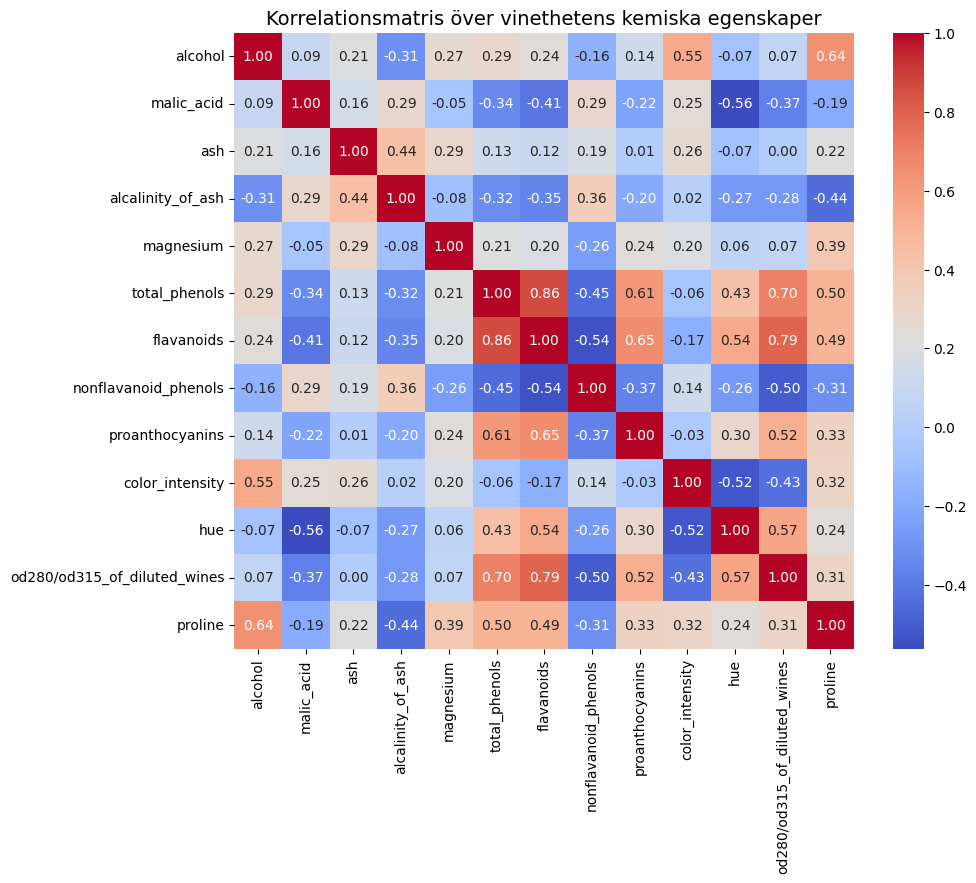

Genererar Pairplot för utvalda nyckelvariabler...


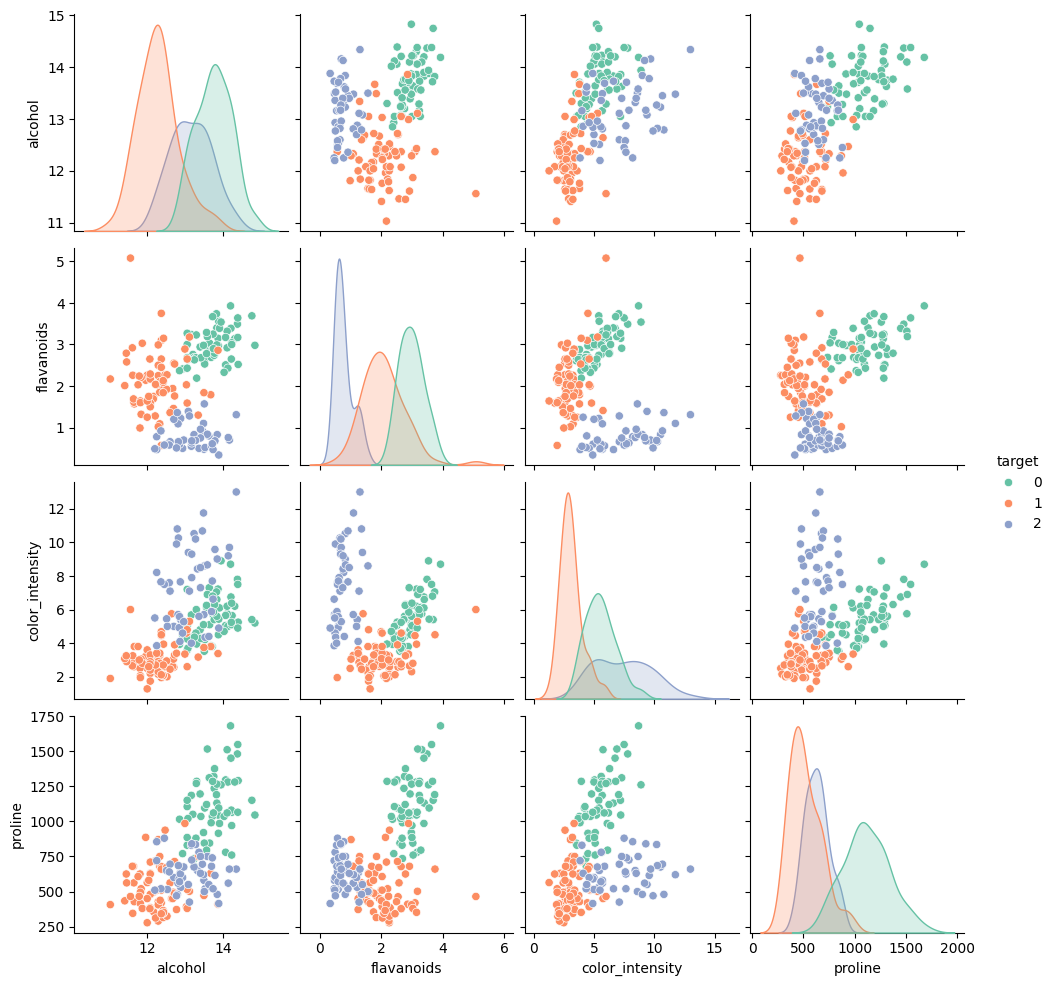

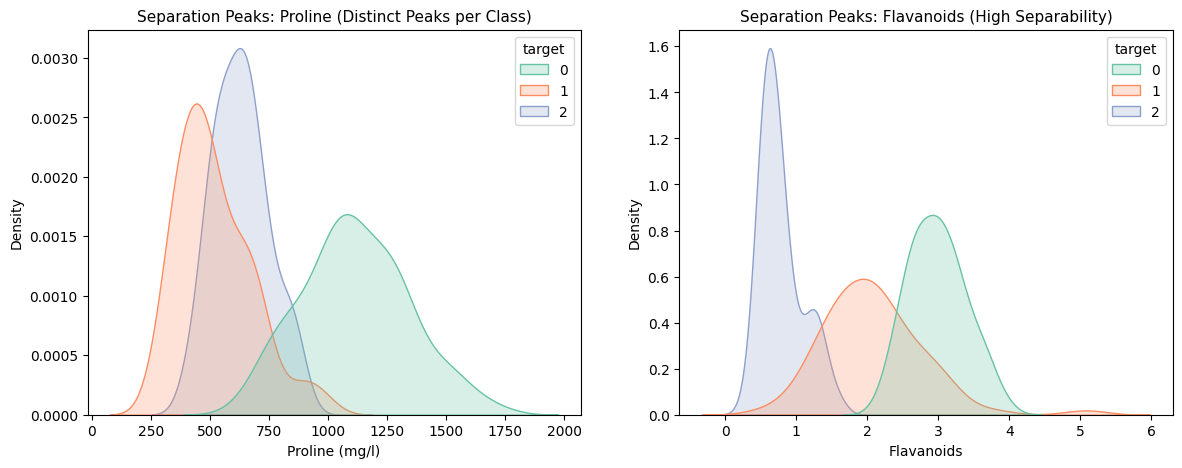

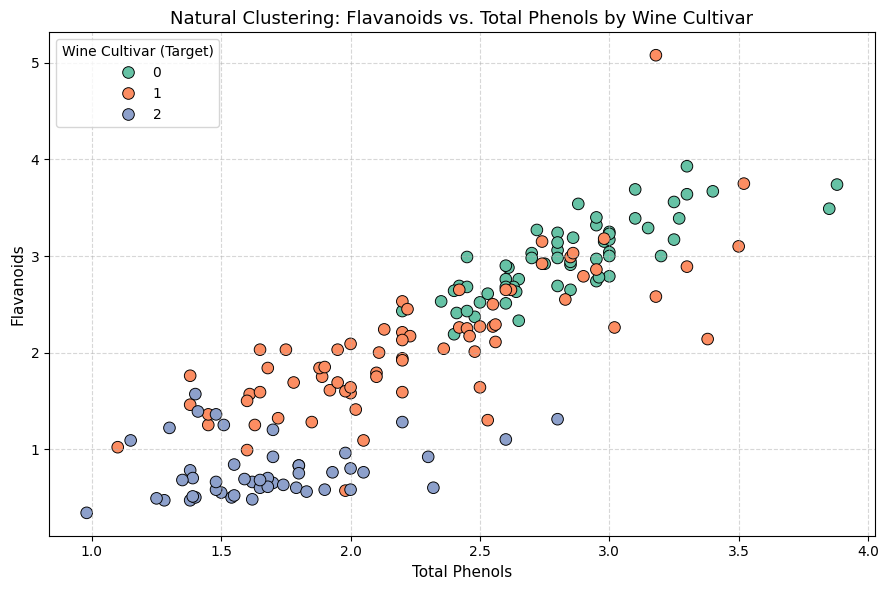

In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

# 1. Ladda Wine-datasetet och förbered data
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

df_vis = X.copy()
df_vis['target'] = y

# ==========================================
# ANALYS & MOTIVERING AV SEPARERBARHET (EDA):
# Hur vet vi att variabler som 'proline' och 'flavanoids' visar god separerbarhet?
# 1. Statistisk spridning: Genom att titta på medelvärden och varians i beskrivande statistik
#    ser man att vissa ämnen skiljer sig markant mellan vinklasserna.
# 2. Fördelningskurvor (KDE-plots): Om klassernas toppar (peaks) hamnar på helt olika
#    ställen på x-axeln med lite överlapp, indikerar det att variabeln är starkt diskriminerande.
# 3. Kluster i spridningsdiagram: I en pairplot bildar dessa variabler tydliga, separata
#    grupper för varje vinklass redan utan maskininlärning.
# ==========================================

# --- A. Korrelationsmatris (Visar linjära samband mellan alla 13 variabler) ---
plt.figure(figsize=(10, 8))
correlation_matrix = X.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Korrelationsmatris över vinethetens kemiska egenskaper", fontsize=14)
plt.show()

# --- B. Pairplot med de mest separerbara/intressanta variablerna ---
# Vi väljer ut några av de starkaste egenskaperna baserat på kemisk profil
selected_features = ['alcohol', 'flavanoids', 'color_intensity', 'proline', 'target']

print("Genererar Pairplot för utvalda nyckelvariabler...")
sns.pairplot(df_vis[selected_features], hue='target', palette='Set2')
plt.show()

# --- C. KDE-plottar för Proline och Flavanoids (Visar tydliga 'Separation Peaks') ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Proline-fördelning per klass
sns.kdeplot(
    data=df_vis,
    x='proline',
    hue='target',
    fill=True,
    common_norm=False,
    palette='Set2',
    ax=axes[0]
)
axes[0].set_title('Separation Peaks: Proline (Distinct Peaks per Class)', fontsize=11)
axes[0].set_xlabel('Proline (mg/l)')
axes[0].set_ylabel('Density')

# 2. Flavanoids-fördelning per klass
sns.kdeplot(
    data=df_vis,
    x='flavanoids',
    hue='target',
    fill=True,
    common_norm=False,
    palette='Set2',
    ax=axes[1]
)
axes[1].set_title('Separation Peaks: Flavanoids (High Separability)', fontsize=11)
axes[1].set_xlabel('Flavanoids')
axes[1].set_ylabel('Density')

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_vis,
    x='total_phenols',
    y='flavanoids',
    hue='target',
    palette='Set2',
    s=70,
    edgecolor='black'
)
# 3. Natural Clustering
plt.title('Natural Clustering: Flavanoids vs. Total Phenols by Wine Cultivar', fontsize=13)
plt.xlabel('Total Phenols', fontsize=11)
plt.ylabel('Flavanoids', fontsize=11)
plt.legend(title='Wine Cultivar (Target)', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()

--- Logistic Regression ---
Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



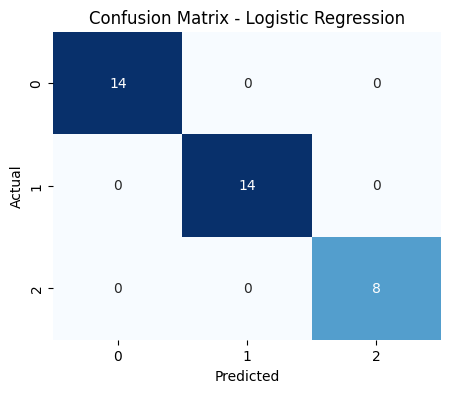

--- Decision Tree ---
Accuracy: 0.9444444444444444

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.93      0.93        14
           1       0.93      1.00      0.97        14
           2       1.00      0.88      0.93         8

    accuracy                           0.94        36
   macro avg       0.95      0.93      0.94        36
weighted avg       0.95      0.94      0.94        36



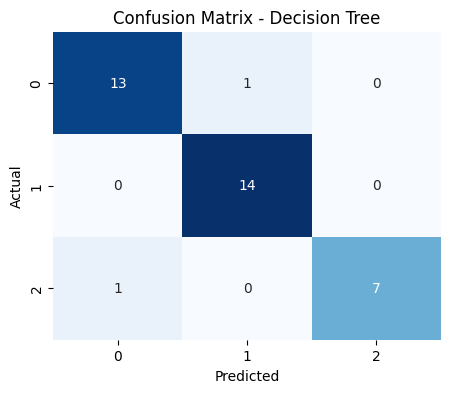

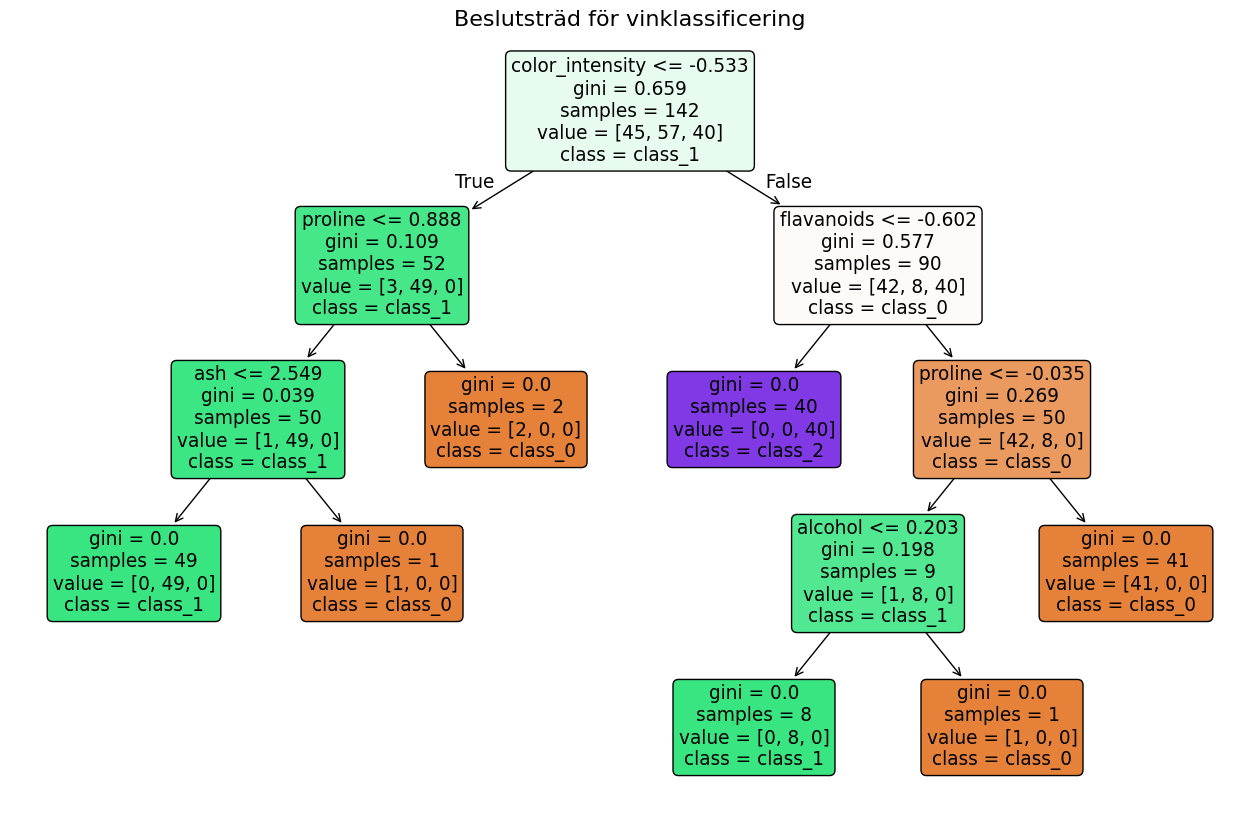

In [20]:
def evaluate_model(model, name):
    print(f"--- {name} ---")
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# A. Logistisk Regression
log_reg = LogisticRegression(random_state=42)
evaluate_model(log_reg, "Logistic Regression")

# B. Beslutsträd (Decision Tree)
tree_clf = DecisionTreeClassifier(random_state=42)
evaluate_model(tree_clf, "Decision Tree")

# Skapa figuren och rita ut trädet
plt.figure(figsize=(16, 10))
plot_tree(
    tree_clf,
    feature_names=wine.feature_names,
    class_names=wine.target_names,
    filled=True,
    rounded=True
)

plt.title("Beslutsträd för vinklassificering", fontsize=16)
plt.show()

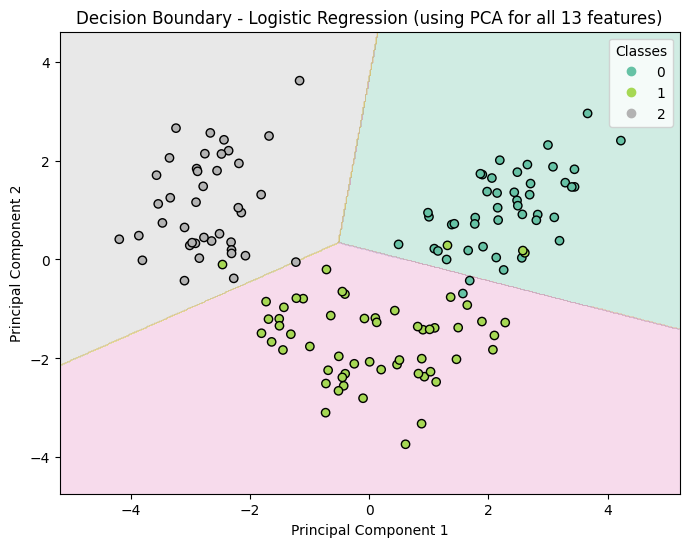

In [7]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# 1. Komprimera alla 13 skalade variabler till 2 dimensioner med PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)

# 2. Träna logistisk regression på PCA-datan
clf_pca = LogisticRegression(random_state=42)
clf_pca.fit(X_train_pca, y_train)

# 3. Skapa rutnät för att rita beslutsgränsen
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

Z = clf_pca.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 4. Rita grafen
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set2)
scatter = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, edgecolors='k', cmap=plt.cm.Set2)
plt.title('Decision Boundary - Logistic Regression (using PCA for all 13 features)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(*scatter.legend_elements(), title="Classes")
plt.show()

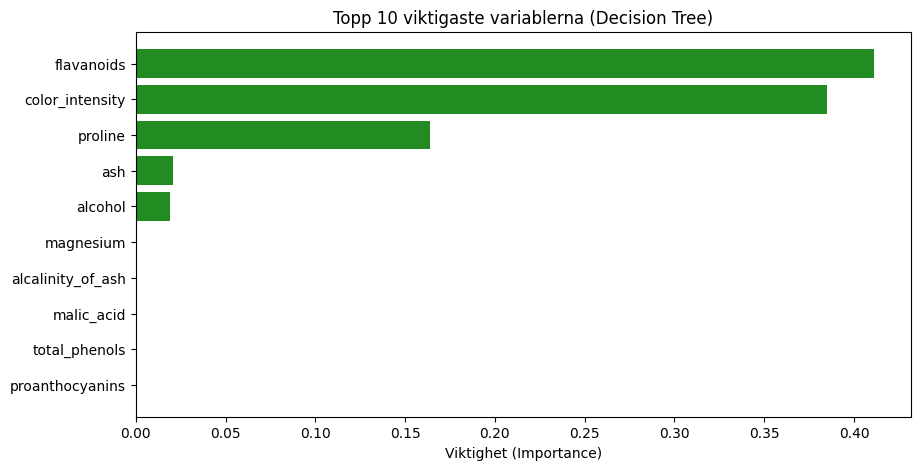

,Feature,Coefficient_Class_0
0,proline,1.040131
1,alcalinity_of_ash,-0.831367
2,alcohol,0.741644
3,Phenol Ratio (OD280/OD315),0.647046
4,flavanoids,0.646226
5,ash,0.498550
6,total_phenols,0.211912
7,proanthocyanins,0.188203
8,color_intensity,0.184843
9,hue,0.163240


In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# A. Feature Importance från Decision Tree
importances = tree_clf.feature_importances_
feature_names = wine.feature_names

# Skapa en snygg tabell/serie för trädets vikter
tree_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Byt namn på variabeln för snyggare visning
tree_imp_df['Feature'] = tree_imp_df['Feature'].replace({
    'od280/od315_of_diluted_wines': 'Phenol Ratio (OD280/OD315)'
})

tree_imp_df = tree_imp_df.sort_values(by='Importance', ascending=False)
plt.figure(figsize=(10, 5))
plt.barh(tree_imp_df['Feature'][:10], tree_imp_df['Importance'][:10], color='forestgreen')
plt.gca().invert_yaxis()
plt.title('Topp 10 viktigaste variablerna (Decision Tree)')
plt.xlabel('Viktighet (Importance)')
plt.show()

# B. Koefficienter från Logistisk Regression (sorterat efter störst absolut påverkan)
log_reg_imp = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient_Class_0': log_reg.coef_[0],
    'Abs_Coefficient': np.abs(log_reg.coef_[0])
})

# Byt namn på kolumnen enbart för visning i tabellen
log_reg_imp['Feature'] = log_reg_imp['Feature'].replace({
    'od280/od315_of_diluted_wines': 'Phenol Ratio (OD280/OD315)'
})

# Sortera efter störst absolutvärde (störst påverkan) och ta de 10 första
log_reg_imp = log_reg_imp.sort_values(by='Abs_Coefficient', ascending=False).head(10)

# (Valfritt) Om du vill rensa bort 'Abs_Coefficient'-kolumnen innan visning:
log_reg_imp = log_reg_imp.drop(columns=['Abs_Coefficient'])

display(log_reg_imp.head(10).reset_index(drop=True))
